## Opgave

Laad de volgende dataset in: heart.csv - deze dataset bevat informatie over patiënten met hartproblemen. 

Pas op deze dataset minstens 2 goede classificatiemethodes toe. Zorg voor preprocessing waar nodig, en zoek naar een optimaal model. **Indien je bepaalde keuzes maakt, schrijf kort in de notebook waarom**.

### Inleveren:
- Hernoem je bestand naar **PE1-VoornaamNaam.ipynb** waarbij je je *eigen naam* invult.
- Laadt dit bestand op naar de uploadzone op toets.ap.be voor het einde van deze test.

Jullie krijgen **60 minuten** de tijd. Bedenk dus dat als de dataset groot is, training lang kan duren. Perfectioneer eerst je model op een kleinere dataset.

### Indicatieve puntenverdeling /20
- goede algoritmes: 2 keer 4 ptn
- goede beschrijving over keuze van deze algoritmes: 4 ptn
- overige noodzakelijke stappen: 8 ptn
- Hierna wordt er gekeken naar code stijl

### Meer info over de features van deze dataset:

- age   Age of the patient in years
- sex 	Gender of the patient (0 = male, 1 = female)
- cp 	Chest pain type:
    - 0: Typical angina
    - 1: Atypical angina
    - 2: Non-anginal pain
    - 3: Asymptomatic
- trestbps 	Resting blood pressure in mm Hg
- chol 	Serum cholesterol in mg/dl
- fbs 	Fasting blood sugar level, categorized as above 120 mg/dl (1 = true, 0 = false)
- restecg 	Resting electrocardiographic results:
    - 0: Normal
    - 1: Having ST-T wave abnormality
    - 2: Showing probable or definite left ventricular hypertrophy
- thalach 	Maximum heart rate achieved during a stress test
- exang 	Exercise-induced angina (1 = yes, 0 = no)
- oldpeak 	ST depression induced by exercise relative to rest
- slope 	Slope of the peak exercise ST segment:
    - 0: Upsloping
    - 1: Flat
    - 2: Downsloping
- ca 	Number of major vessels (0-4) colored by fluoroscopy
- thal 	Thalium stress test result:
    - 0: Normal
    - 1: Fixed defect
    - 2: Reversible defect
    - 3: Not described
- **target** 	Heart disease status (0 = no disease, 1 = presence of disease)

In [63]:
import pandas as pd
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import classification_report,ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier


In [46]:
df = pd.read_csv('heart.csv')

In [ ]:
# ik wil een overzicht over de data krijgen
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [48]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [49]:
X = df.drop(['target'],axis=1)
y = df['target']

In [ ]:
# ik maak mijn testdata 0.33 zodat er genoeg test is en er minder kans is op overfitting
# stratify doe ik zodat alles goed gebalanceerd is en niet perongeluk 1zijdig word
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=1,stratify=y)

In [51]:
# ik begin met svc omdat het doel binair is en het een kleine dataset is
# de dataset is ook vrij evenwichtig 
pipe_svc = Pipeline([('scaler',StandardScaler()),('svc',SVC(random_state=1))])

              precision    recall  f1-score   support

           0       0.84      0.83      0.84        46
           1       0.85      0.87      0.86        54

    accuracy                           0.85       100
   macro avg       0.85      0.85      0.85       100
weighted avg       0.85      0.85      0.85       100



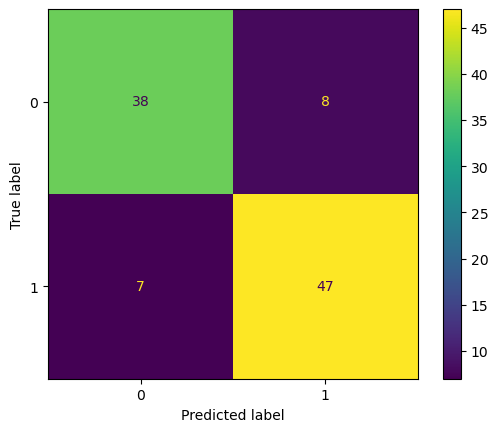

In [53]:
pipe_svc.fit(X_train,y_train)
y_pred = pipe_svc.predict(X_test)
print(classification_report(y_test,y_pred))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)

In [ ]:
pipe_knn = Pipeline([('scaler',StandardScaler()),('knn',KNeighborsClassifier())])

              precision    recall  f1-score   support

           0       0.80      0.80      0.80        46
           1       0.83      0.83      0.83        54

    accuracy                           0.82       100
   macro avg       0.82      0.82      0.82       100
weighted avg       0.82      0.82      0.82       100



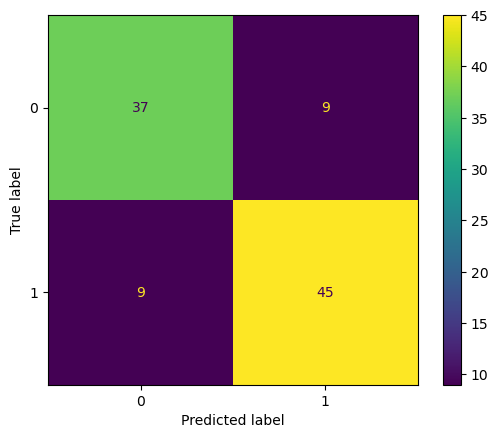

In [59]:
pipe_knn.fit(X_train,y_train)
y_pred = pipe_knn.predict(X_test)
print(classification_report(y_test,y_pred))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)

In [ ]:
# ik zie hier dat beide modellen vrij goed presteren maar knn iets minder.
# misschien met gridsearch vind ik betere hyperparameters

In [ ]:
params_svc = {'svc__C': [0.01,0.1,1,10],
              'svc__kernel':['linear', 'poly', 'rbf', 'sigmoid'],
              'svc__degree': [1,2,3,4,5]}
params_knn  = {'knn__n_neighbors':[2,3,4,5,6]}

              precision    recall  f1-score   support

           0       0.90      0.76      0.82        46
           1       0.82      0.93      0.87        54

    accuracy                           0.85       100
   macro avg       0.86      0.84      0.85       100
weighted avg       0.86      0.85      0.85       100

{'svc__C': 0.01, 'svc__degree': 1, 'svc__kernel': 'linear'}


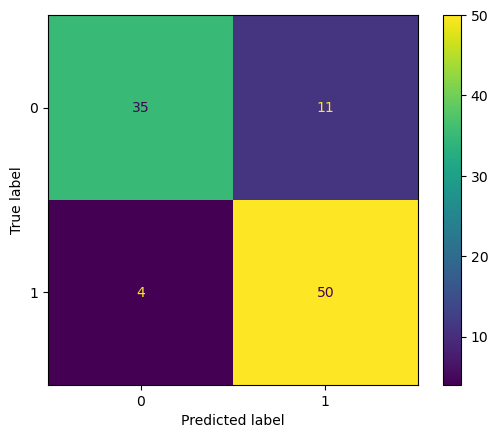

In [ ]:
grid = GridSearchCV(pipe_svc,params_svc,cv=3,scoring='accuracy')
grid.fit(X_train,y_train)
y_pred = grid.predict(X_test)
print(classification_report(y_test,y_pred))
print(grid.best_params_)
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)

# hier zie ik wel dat de we veel minder false negatives krijgen, afhankelijk van de situatie maakt dit het betere model.
# op dit moment zou ik dan aan mijn opdrachtgever de 2 svc modellen voorstellen
# en vragen of ze de false negatives willen priorizeren of gebalanceert houden 
# dit kan belangrijk zijn voor de kosten
# zelf zou ik dit model pakken omdat de true positives het belangrijkste zijn 
# elke true positif is een leven dat gered kan worden

              precision    recall  f1-score   support

           0       0.78      0.85      0.81        46
           1       0.86      0.80      0.83        54

    accuracy                           0.82       100
   macro avg       0.82      0.82      0.82       100
weighted avg       0.82      0.82      0.82       100

{'knn__n_neighbors': 4}


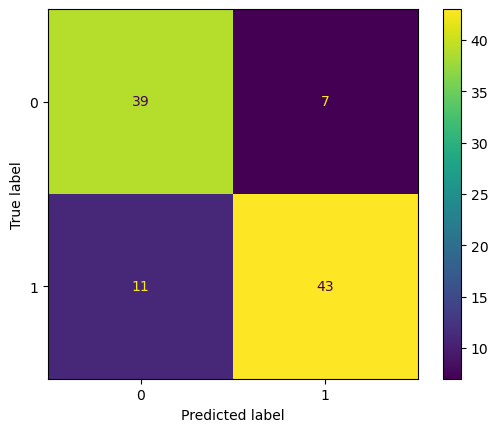

In [80]:
grid = GridSearchCV(pipe_knn,params_knn,cv=3,scoring='accuracy')
grid.fit(X_train,y_train)
y_pred = grid.predict(X_test)
print(classification_report(y_test,y_pred))
print(grid.best_params_)
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)

In [ ]:
# we zien wel dat knn iets anders scoort maar niet dat het model echt beter genoemt kan worden.
# terwijl bij svc dat de standaard params als goed genoeg waren.
# met een grotere dataset zouden we hier beter op kunnen trainen maar ik denk met de huidige set is dit alles wat ons kan brengen.

# mijn eindconclusie ligt bij svc met gridsearch 
# dit levert een model op dat true positives het hoogste haalt en false negatives ook het laagste houd.